# Multi-modal RAG with LangChain

## SetUp

Install the dependencies you need to run the notebook.

In [ ]:
# for linux
# !apt-get install poppler-utils tesseract-ocr libmagic-dev

# for mac
# !brew install poppler tesseract libmagic

In [1]:
!pip install -Uq "unstructured[all-docs]" pillow lxml pillow
!pip install -Uq chromadb tiktoken
!pip install -Uq langchain langchain-community langchain-openai langchain-groq
!pip install -Uq python_dotenv


  DEPRECATION: Building 'langdetect' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'langdetect'. Discussion can be found at https://github.com/pypa/pip/issues/6334
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
easyocr 1.7.2 requires opencv-python-headless, which is not installed.
imgaug 0.4.0 requires opencv-python, which is not installed.
roboflow 1.2.6 requires opencv-python-headless==4.10.0.84, which is not installed.
supervision 0.26.1 requires opencv-python>=4.5.5.64, which is not installed.
ultralytics 8.3.184 requires opencv-python>=4.6.0, which is not insta

## Extract the data

Extract the elements of the PDF that we will be able to use in the retrieval process. These elements can be: Text, Images, Tables, etc.

### Partition PDF tables, text, and images

In [1]:
from unstructured.partition.pdf import partition_pdf

output_path = "./content/"
file_path = 'attention.pdf'

# Reference: https://docs.unstructured.io/open-source/core-functionality/chunking
chunks = partition_pdf(
    filename=file_path,
    infer_table_structure=True,            # extract tables
    strategy="hi_res",                     # mandatory to infer tables

    extract_image_block_types=["Image"],   # Add 'Table' to list to extract image of tables
    # image_output_dir_path=output_path,   # if None, images and tables will saved in base64

    extract_image_block_to_payload=True,   # if true, will extract base64 for API usage

    chunking_strategy="by_title",          # or 'basic'
    max_characters=10000,                  # defaults to 500
    combine_text_under_n_chars=2000,       # defaults to 0
    new_after_n_chars=6000,

    # extract_images_in_pdf=True,          # deprecated
)

c:\Users\rajde\anaconda3\envs\langchain\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
No languages specified, defaulting to English.
Loading weights: 100%|██████████| 367/367 [00:00<00:00, 3002.44it/s]


In [2]:
# We get 2 types of elements from the partition_pdf function
set([str(type(el)) for el in chunks])

{"<class 'unstructured.documents.elements.CompositeElement'>",
 "<class 'unstructured.documents.elements.Table'>"}

In [3]:
# Each CompositeElement containes a bunch of related elements.
# This makes it easy to use these elements together in a RAG pipeline.

chunks[3].metadata.orig_elements

In [4]:
# This is what an extracted image looks like.
# It contains the base64 representation only because we set the param extract_image_block_to_payload=True

elements = chunks[3].metadata.orig_elements
chunk_images = [el for el in elements if 'Image' in str(type(el))]
chunk_images[0].to_dict()

{'type': 'Image',
 'element_id': '8e044e32-8839-4884-8889-ce7b1ca5505e',
 'text': '',
 'metadata': {'coordinates': {'points': ((np.float64(850.5),
     np.float64(457.0659722222226)),
    (np.float64(850.5), np.float64(1075.8659722222224)),
    (np.float64(1162.0), np.float64(1075.8659722222224)),
    (np.float64(1162.0), np.float64(457.0659722222226))),
   'system': 'PixelSpace',
   'layout_width': 2975,
   'layout_height': 3850},
  'last_modified': '2026-09-17T22:08:33',
  'filetype': 'PNG',
  'languages': ['eng'],
  'page_number': 4,
  'image_base64': '...',
  'image_mime_type': 'image/jpeg'}}

### Separate extracted elements into tables, text, and images

In [5]:
# separate tables from texts
tables = []
texts = []    ## Composite Elements

for chunk in chunks:
    if "Table" in str(type(chunk)):
        tables.append(chunk)

    if "CompositeElement" in str(type((chunk))):
        texts.append(chunk)

In [6]:
# Get the images from the CompositeElement objects
def get_images_base64(chunks):
    images_b64 = []
    for chunk in chunks:
        if "CompositeElement" in str(type(chunk)):
            chunk_els = chunk.metadata.orig_elements
            for el in chunk_els:
                if "Image" in str(type(el)):
                    images_b64.append(el.metadata.image_base64)
    return images_b64

images = get_images_base64(chunks)

#### Check what the images look like

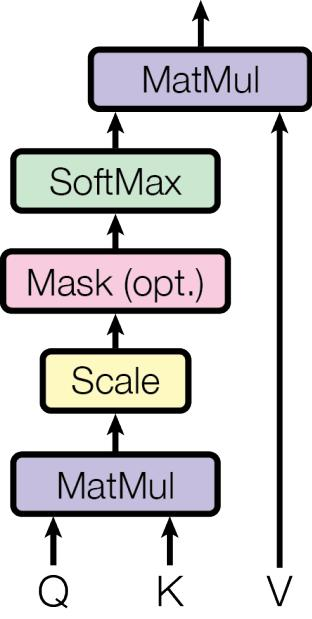

In [7]:
import base64
from IPython.display import Image, display

def display_base64_image(base64_code):
    # Decode the base64 string to binary
    image_data = base64.b64decode(base64_code)
    # Display the image
    display(Image(data=image_data))

display_base64_image(images[1])

## Summarize the data

Create a summary of each element extracted from the PDF. This summary will be vectorized and used in the retrieval process.

### Text and Table summaries

We don't need a multimodal model to generate the summaries of the tables and the text. I will use open source models available on Groq.

In [13]:
!pip show langchain-groq

Name: langchain-groq
Version: 1.1.3
Summary: An integration package connecting Groq and LangChain
Home-page: https://docs.langchain.com/oss/python/integrations/providers/groq
Author: 
Author-email: 
License: MIT
Location: C:\Users\rajde\anaconda3\envs\langchain\Lib\site-packages
Requires: groq, langchain-core
Required-by: 


In [8]:
from langchain_groq import ChatGroq
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

In [ ]:
# Prompt
prompt_text = """
You are an assistant tasked with summarizing tables and text.
Give a concise summary of the table or text.

Respond only with the summary, no additionnal comment.
Do not start your message by saying "Here is a summary" or anything like that.
Just give the summary as it is.

Table or text chunk: {element}

"""
prompt = ChatPromptTemplate.from_template(prompt_text)

# Summary chain
model = ChatGroq(temperature=0.5, model="openai/gpt-oss-20b", api_key="")
summarize_chain = {"element": lambda x: x} | prompt | model | StrOutputParser()

In [10]:
# Summarize text
text_summaries = summarize_chain.batch(texts, {"max_concurrency": 3})

In [11]:
## Summarize tables
# Summarize tables
tables_html = [table.metadata.text_as_html for table in tables]
table_summaries = summarize_chain.batch(tables_html, {"max_concurrency": 3})

In [12]:
text_summaries

['Transformer: a neural architecture that replaces recurrent and convolutional networks with self‑attention only. It achieves higher translation quality (28.4 BLEU on WMT’14 En→De, 41.0 BLEU on En→Fr) while training faster and allowing greater parallelism. The paper introduces scaled dot‑product and multi‑head attention, position‑encoding, and reports state‑of‑the‑art results with a single model trained in just a few days on eight GPUs.',
 'The Transformer replaces sequential RNNs and convolutions with pure self‑attention, achieving constant‑time interactions between any two positions (vs. linear in ConvS2S and logarithmic in ByteNet). Self‑attention has proven effective in many NLP tasks, and the Transformer is the first end‑to‑end transduction model to rely solely on it. It follows a standard encoder‑decoder framework: the encoder maps input symbols to continuous representations, and the decoder generates outputs autoregressively, both using stacked self‑attention layers followed by 

In [13]:
table_summaries

['Layer types and their computational characteristics:  \n- Self‑Attention: per‑layer complexity O(n\u202f–\u202fd), constant sequential operations, constant maximum path length.  \n- Recurrent: per‑layer complexity O(n\u202f–\u202fd), sequential operations O(n), maximum path length O(n).  \n- Convolutional: per‑layer complexity O(k\u202f–\u202fn\u202f–\u202fd), constant sequential operations, maximum path length O(log\u202fn).  \n- Restricted Self‑Attention: per‑layer complexity O(r\u202f–\u202fn\u202f–\u202fd), constant sequential operations, maximum path length O(n/r).',
 'The table compares neural machine translation models on English‑German (EN‑DE) and English‑French (EN‑FR) tasks, listing BLEU scores and training FLOPs. ByteNet achieves 23.75 BLEU on EN‑DE. Models using attention and positional unknown tokens reach 39.2 BLEU on EN‑FR. GNMT with reinforcement learning attains 24.6 BLEU (EN‑DE) and 39.92 BLEU (EN‑FR). Convolutional sequence‑to‑sequence (ConvS2S) and Mixture‑of‑Expe

### Image summaries

We will use gpt-4o-mini to produce the image summaries.

In [ ]:
from langchain_openai import ChatOpenAI
import os

model = ChatOpenAI(
    model="qwen/qwen3.7-flash:free",
    base_url="https://api.xkiro.com/v1",
    api_key="",
    temperature=0,
)

In [15]:
prompt_template = """Describe the image in detail. For context,
                  the image is part of a research paper explaining the transformers
                  architecture. Be specific about graphs, such as bar plots."""
messages = [
    (
        "user",
        [
            {"type": "text", "text": prompt_template},
            {
                "type": "image_url",
                "image_url": {"url": "data:image/jpeg;base64,{image}"},
            },
        ],
    )
]

prompt = ChatPromptTemplate.from_messages(messages)

chain = prompt | model | StrOutputParser()


import time

image_summaries = []

for index, image in enumerate(images, start=1):
    try:
        summary = chain.invoke(image)
        image_summaries.append(summary)
        print(f"Processed image {index}/{len(images)}")
        time.sleep(2)  # helps avoid Groq rate limits
    except Exception as error:
        print(f"Image {index} failed: {error}")
        image_summaries.append("")

Processed image 1/3
Processed image 2/3
Processed image 3/3


In [16]:
image_summaries

['This image is a schematic diagram illustrating the architecture of the Transformer model, specifically detailing the Encoder-Decoder structure as presented in the "Attention Is All You Need" paper. The diagram flows from bottom to top and is divided into two main vertical stacks: the Encoder on the left and the Decoder on the right.\n\n**Left Stack: The Encoder**\n*   **Inputs:** At the bottom, an arrow labeled "Inputs" points upward into a pink rectangle labeled "Input Embedding."\n*   **Positional Encoding:** The output of the embedding layer is combined with "Positional Encoding" (represented by a circle containing a sine wave symbol) via an addition operation (indicated by a circle with a plus sign).\n*   **Encoder Layer Block:** The combined signal enters a large rounded rectangle representing the encoder layer. This block is labeled "N×" on its left side, indicating that this stack of layers is repeated N times.\n    *   **Multi-Head Attention:** Inside the block, the data firs

In [17]:
print(image_summaries[0])

This image is a schematic diagram illustrating the architecture of the Transformer model, specifically detailing the Encoder-Decoder structure as presented in the "Attention Is All You Need" paper. The diagram flows from bottom to top and is divided into two main vertical stacks: the Encoder on the left and the Decoder on the right.

**Left Stack: The Encoder**
*   **Inputs:** At the bottom, an arrow labeled "Inputs" points upward into a pink rectangle labeled "Input Embedding."
*   **Positional Encoding:** The output of the embedding layer is combined with "Positional Encoding" (represented by a circle containing a sine wave symbol) via an addition operation (indicated by a circle with a plus sign).
*   **Encoder Layer Block:** The combined signal enters a large rounded rectangle representing the encoder layer. This block is labeled "N×" on its left side, indicating that this stack of layers is repeated N times.
    *   **Multi-Head Attention:** Inside the block, the data first passes

In [18]:
chunks[0].metadata.orig_elements

In [19]:
chunks[0].metadata.orig_elements[13].text

'Abstract'

### Semantic Chunking

In [24]:
!pip install sentence-transformers

   ---------------------------------------- 0.0/740.6 kB ? eta -:--:--
   ---------------------------------------- 740.6/740.6 kB 10.2 MB/s  0:00:00


In [20]:
from sentence_transformers import SentenceTransformer
from langchain_experimental.text_splitter import SemanticChunker

embedder = SentenceTransformer("NeuML/biomedbert-small-embeddings")

# for semantic chunking (boundary detection)
from langchain_huggingface import HuggingFaceEmbeddings
tiny_embedder = HuggingFaceEmbeddings(model_name="NeuML/biomedbert-small-embeddings")

C:\Users\rajde\AppData\Local\Temp\ipykernel_29292\1521229406.py:2: DeprecationWarning: `langchain-experimental` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-experimental/issues/87 for details.
  from langchain_experimental.text_splitter import SemanticChunker
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6802.18it/s]


### Coordinate-aware semantic child chunks

The code below treats each item in a parent chunk's `orig_elements` as an ordered unit. Titles always begin a new child chunk; other elements are appended when their embedding is similar to the current child. Short non-title elements are retained even when they fall below the similarity threshold. Parent and child metadata, including all source coordinates, are stored in SQLite.

In [22]:
import json
import re
import sqlite3
import uuid
from pathlib import Path

import numpy as np

SEMANTIC_SIMILARITY_THRESHOLD = 0.70
SHORT_ELEMENT_LIMIT = 50
MIN_CHILD_CHARS = 50
SQLITE_PATH = Path("semantic_chunks_final.db")
ABBREVIATIONS = {
    "dr", "mr", "mrs", "ms", "prof", "fig", "vs", "etc",
    "eg", "ie", "no", "al", "vol", "approx", "st",
}


def element_text(element):    ## Get the text in the element in str format
    value = getattr(element, "text", None)
    if value is None:
        value = str(element) if isinstance(element, str) else ""
    return " ".join(str(value).split())


def element_category(element):    ## Get the category of the element in str format like "Title", "NarrativeText", "Table", etc.
    category = getattr(getattr(element, "metadata", None), "category", None)
    return str(category or element.__class__.__name__)

 
def is_title(element):     ## Check if the category is Title
    return (
        element_category(element).lower() == "title"
        or "title" in element.__class__.__name__.lower()
    )


def point_to_dict(point):
    if isinstance(point, dict):
        return point
    if hasattr(point, "x") and hasattr(point, "y"):
        return {"x": point.x, "y": point.y}
    if isinstance(point, (tuple, list)) and len(point) >= 2:
        return {"x": point[0], "y": point[1]}
    return {"value": str(point)}


def element_coordinates(element):      ## Give the page_num and coordinates of each element in dict format
    metadata = getattr(element, "metadata", None)
    page_number = getattr(metadata, "page_number", None)
    coordinates = getattr(metadata, "coordinates", None)
    points = getattr(coordinates, "points", None) if coordinates is not None else None

    if isinstance(metadata, dict):
        page_number = metadata.get("page_number", page_number)
    if points is None and isinstance(coordinates, dict):
        points = coordinates.get("points", [])

    return {
        "page_num": page_number,
        "points": [point_to_dict(point) for point in (points or [])],
    }


def element_metadata(element):       ### Metadata of each element to be stored with the child chunk in dict format
    metadata = getattr(element, "metadata", None)
    if metadata is None:
        return {}
    if hasattr(metadata, "to_dict"):
        raw_metadata = metadata.to_dict()
    elif isinstance(metadata, dict):
        raw_metadata = metadata
    else:
        raw_metadata = {"value": str(metadata)}
    return json.loads(json.dumps(raw_metadata, default=str))


def split_element_sentences(element):     ## Split an element into sentences based on punctuation and abbreviations
    text = element_text(element)
    if not text:
        return [""]

    parts = re.split(r"(?<=[.!?。！？])\s+", text)
    sentences = []
    buffer = ""
    for part in parts:
        buffer = f"{buffer} {part}".strip() if buffer else part
        last_word = re.findall(r"([A-Za-z]+)\.$", buffer)
        if last_word and last_word[0].lower() in ABBREVIATIONS:
            continue
        sentences.append(buffer)
        buffer = ""
    if buffer:
        sentences.append(buffer)
    return [sentence.strip() for sentence in sentences if sentence.strip()]


def cosine_similarity(left, right):
    left_norm = np.linalg.norm(left)
    right_norm = np.linalg.norm(right)
    if left_norm == 0 or right_norm == 0:
        return 0.0
    return float(np.dot(left, right) / (left_norm * right_norm))


def merge_small_children(child_records, min_chars=MIN_CHILD_CHARS):
    merged = []
    for child in child_records:
        previous = merged[-1] if merged else None
        if (
            previous is not None
            and previous["parent_id"] == child["parent_id"]
            and len(child["text"]) < min_chars
        ):
            previous["text"] = f'{previous["text"]} {child["text"]}'.strip()
            previous["coordinates"].extend(child["coordinates"])
            previous["element_metadata"].extend(child["element_metadata"])
            previous["element_count"] += child["element_count"]
        else:
            merged.append(child)

    positions = {}
    for child in merged:
        parent_id = child["parent_id"]
        positions[parent_id] = positions.get(parent_id, -1) + 1
        child["child_position"] = positions[parent_id]
    return merged


def build_semantic_children(
    parent_chunks,
    embedding_model,
    similarity_threshold=SEMANTIC_SIMILARITY_THRESHOLD,
    min_child_chars=MIN_CHILD_CHARS,
):
    parent_records = []
    child_records = []

    for parent_position, parent in enumerate(parent_chunks):
        parent_id = str(uuid.uuid4())
        original_elements = list(
            getattr(getattr(parent, "metadata", None), "orig_elements", []) or []
        )
        parent_records.append({
            "parent_id": parent_id,
            "parent_position": parent_position,
            "text": element_text(parent),
            "element_count": len(original_elements),
            "coordinates": [element_coordinates(element) for element in original_elements],
            "metadata": element_metadata(parent),
        })

        current_elements = []
        current_text_parts = []
        current_embedding = None
        embedding_count = 0
        force_attach_next = False

        def flush_child():
            nonlocal current_elements, current_text_parts, current_embedding
            nonlocal embedding_count, force_attach_next
            if not current_elements:
                return
            child_records.append({
                "child_id": str(uuid.uuid4()),
                "parent_id": parent_id,
                "child_position": len([
                    item for item in child_records
                    if item["parent_id"] == parent_id
                ]),
                "text": " ".join(current_text_parts).strip(),
                "element_count": len(current_elements),
                "coordinates": [
                    element_coordinates(element) for element in current_elements
                ],
                "element_metadata": [
                    element_metadata(element) for element in current_elements
                ],
            })
            current_elements = []
            current_text_parts = []
            current_embedding = None
            embedding_count = 0
            force_attach_next = False

        def append_to_current(element, sentence, sentence_embedding):
            nonlocal current_embedding, embedding_count
            current_elements.append(element)
            current_text_parts.append(sentence)
            if sentence_embedding is None:
                return
            if current_embedding is None:
                current_embedding = sentence_embedding
                embedding_count = 1
            else:     ## Average the embeddings of the current elements with the new sentence embedding so that we do not need to calculate the embedding of the entire current text again
                current_embedding = (
                    current_embedding * embedding_count + sentence_embedding
                ) / (embedding_count + 1)
                embedding_count += 1

        for element in original_elements:
            for sentence in split_element_sentences(element):
                if is_title(element):
                    flush_child()
                    append_to_current(
                        element,
                        sentence,
                        embedding_model.encode(sentence, normalize_embeddings=True),
                    )
                    force_attach_next = True
                    continue

                if not sentence:
                    if current_elements:
                        append_to_current(element, sentence, None)
                    continue

                sentence_embedding = embedding_model.encode(
                    sentence,
                    normalize_embeddings=True,
                )
                if not current_elements:
                    append_to_current(element, sentence, sentence_embedding)
                    continue

                if force_attach_next:
                    append_to_current(element, sentence, sentence_embedding)
                    force_attach_next = False
                    continue

                similarity = cosine_similarity(current_embedding, sentence_embedding)
                if len(sentence) < SHORT_ELEMENT_LIMIT or similarity >= similarity_threshold:
                    append_to_current(element, sentence, sentence_embedding)
                else:
                    flush_child()
                    append_to_current(element, sentence, sentence_embedding)

        flush_child()

    return parent_records, merge_small_children(
        child_records,
        min_chars=min_child_chars,
    )


parent_records, child_records = build_semantic_children(chunks, embedder)

with sqlite3.connect(SQLITE_PATH) as connection:
    connection.execute("PRAGMA foreign_keys = ON")
    connection.executescript("""
        DROP TABLE IF EXISTS child_chunks;
        DROP TABLE IF EXISTS parent_documents;
        CREATE TABLE parent_documents (
            parent_id TEXT PRIMARY KEY,
            parent_position INTEGER NOT NULL,
            text TEXT NOT NULL,
            element_count INTEGER NOT NULL,
            coordinates_json TEXT NOT NULL,
            metadata_json TEXT NOT NULL
        );
        CREATE TABLE child_chunks (
            child_id TEXT PRIMARY KEY,
            parent_id TEXT NOT NULL,
            child_position INTEGER NOT NULL,
            text TEXT NOT NULL,
            element_count INTEGER NOT NULL,
            coordinates_json TEXT NOT NULL,
            element_metadata_json TEXT NOT NULL,
            FOREIGN KEY (parent_id) REFERENCES parent_documents(parent_id)
        );
        CREATE INDEX idx_child_chunks_parent_id ON child_chunks(parent_id);
    """)
    connection.executemany(
        """INSERT INTO parent_documents
        (parent_id, parent_position, text, element_count, coordinates_json, metadata_json)
        VALUES (?, ?, ?, ?, ?, ?)""",
        [
            (
                record["parent_id"],
                record["parent_position"],
                record["text"],
                record["element_count"],
                json.dumps(record["coordinates"], default=str),
                json.dumps(record["metadata"], default=str),
            )
            for record in parent_records
        ],
    )
    connection.executemany(
        """INSERT INTO child_chunks
        (child_id, parent_id, child_position, text, element_count, coordinates_json, element_metadata_json)
        VALUES (?, ?, ?, ?, ?, ?, ?)""",
        [
            (
                record["child_id"],
                record["parent_id"],
                record["child_position"],
                record["text"],
                record["element_count"],
                json.dumps(record["coordinates"], default=str),
                json.dumps(record["element_metadata"], default=str),
            )
            for record in child_records
        ],
    )
    connection.commit()

print(f"Created {len(parent_records)} parents and {len(child_records)} child chunks")
print(f"SQLite database: {SQLITE_PATH.resolve()}")

Created 13 parents and 160 child chunks
SQLite database: C:\Users\rajde\Documents\NLP_Lab_Assignments_sem_5\semantic_chunks_final.db


In [ ]:
from langchain_openai import OpenAIEmbeddings
embedding_model = OpenAIEmbeddings(
  model="text-embedding-medembed-large-v0.1",
  base_url="http://127.0.0.1:1234/v1",
  api_key="",
  check_embedding_ctx_length=False
)

In [23]:
text_query = "What is Retrieval-Augmented Generation?"
query_vector = embedding_model.embed_query(text_query)
print("Query Vector (first 3 dimensions):", query_vector[:3])
print("Vector Length:", len(query_vector))

Query Vector (first 3 dimensions): [-0.01016265619546175, 0.011578692123293877, -0.010340449400246143]
Vector Length: 1024


In [31]:
chunks[2].metadata.orig_elements[5].text

'wise fully connected feed-forward network. We employ a residual connection [10] around each of the two sub-layers, followed by layer normalization [1]. That is, the output of each sub-layer is LayerNorm(x + Sublayer(x)), where Sublayer(x) is the function implemented by the sub-layer itself. To facilitate these residual connections, all sub-layers in the model, as well as the embedding layers, produce outputs of dimension dmodel = 512.'

In [32]:
split_element_sentences(chunks[2].metadata.orig_elements[5].text)

['wise fully connected feed-forward network.',
 'We employ a residual connection [10] around each of the two sub-layers, followed by layer normalization [1].',
 'That is, the output of each sub-layer is LayerNorm(x + Sublayer(x)), where Sublayer(x) is the function implemented by the sub-layer itself.',
 'To facilitate these residual connections, all sub-layers in the model, as well as the embedding layers, produce outputs of dimension dmodel = 512.']

### Qdrant

## Load data and summaries to vectorstore

### Create the vectorstore

In [ ]:
import uuid
from langchain.vectorstores import Chroma
from langchain.storage import InMemoryStore
from langchain.schema.document import Document
from langchain.embeddings import OpenAIEmbeddings
from langchain.retrievers.multi_vector import MultiVectorRetriever

# The vectorstore to use to index the child chunks
vectorstore = Chroma(collection_name="multi_modal_rag", embedding_function=OpenAIEmbeddings())

# The storage layer for the parent documents
store = InMemoryStore()
id_key = "doc_id"

# The retriever (empty to start)
retriever = MultiVectorRetriever(
    vectorstore=vectorstore,
    docstore=store,
    id_key=id_key,
)

/var/folders/lh/7g2mv_x16p79z2rd9jqxqx_w0000gn/T/ipykernel_92745/278287695.py:9: LangChainDeprecationWarning: The class `OpenAIEmbeddings` was deprecated in LangChain 0.0.9 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-openai package and should be used instead. To use it run `pip install -U :class:`~langchain-openai` and import as `from :class:`~langchain_openai import OpenAIEmbeddings``.
  vectorstore = Chroma(collection_name="multi_modal_rag", embedding_function=OpenAIEmbeddings())
/var/folders/lh/7g2mv_x16p79z2rd9jqxqx_w0000gn/T/ipykernel_92745/278287695.py:9: LangChainDeprecationWarning: The class `Chroma` was deprecated in LangChain 0.2.9 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-chroma package and should be used instead. To use it run `pip install -U :class:`~langchain-chroma` and import as `from :class:`~langchain_chroma import Chroma``.
  vectorstore = Chroma(collection_name="multi

### Load the summaries and link the to the original data

In [ ]:
# Add texts
doc_ids = [str(uuid.uuid4()) for _ in texts]
summary_texts = [
    Document(page_content=summary, metadata={id_key: doc_ids[i]}) for i, summary in enumerate(text_summaries)
]
retriever.vectorstore.add_documents(summary_texts)
retriever.docstore.mset(list(zip(doc_ids, texts)))

# Add tables
table_ids = [str(uuid.uuid4()) for _ in tables]
summary_tables = [
    Document(page_content=summary, metadata={id_key: table_ids[i]}) for i, summary in enumerate(table_summaries)
]
retriever.vectorstore.add_documents(summary_tables)
retriever.docstore.mset(list(zip(table_ids, tables)))

# Add image summaries
img_ids = [str(uuid.uuid4()) for _ in images]
summary_img = [
    Document(page_content=summary, metadata={id_key: img_ids[i]}) for i, summary in enumerate(image_summaries)
]
retriever.vectorstore.add_documents(summary_img)
retriever.docstore.mset(list(zip(img_ids, images)))

### Check retrieval

In [ ]:
# Retrieve
docs = retriever.invoke(
    "who are the authors of the paper?"
)

In [ ]:
for doc in docs:
    print(str(doc) + "\n\n" + "-" * 80)

[36] Christian Szegedy, Vincent Vanhoucke, Sergey Ioffe, Jonathon Shlens, and Zbigniew Wojna. Rethinking the inception architecture for computer vision. CoRR, abs/1512.00567, 2015.

[37] Vinyals & Kaiser, Koo, Petrov, Sutskever, and Hinton. Grammar as a foreign language. In Advances in Neural Information Processing Systems, 2015.

[38] Yonghui Wu, Mike Schuster, Zhifeng Chen, Quoc V Le, Mohammad Norouzi, Wolfgang Macherey, Maxim Krikun, Yuan Cao, Qin Gao, Klaus Macherey, et al. Google’s neural machine translation system: Bridging the gap between human and machine translation. arXiv preprint arXiv:1609.08144, 2016.

[39] Jie Zhou, Ying Cao, Xuguang Wang, Peng Li, and Wei Xu. Deep recurrent models with fast-forward connections for neural machine translation. CoRR, abs/1606.04199, 2016.

[40] Muhua Zhu, Yue Zhang, Wenliang Chen, Min Zhang, and Jingbo Zhu. Fast and accurate shift-reduce constituent parsing. In Proceedings of the 51st Annual Meeting of the ACL (Volume 1: Long Papers), pages

## RAG pipeline

In [ ]:
from langchain_core.runnables import RunnablePassthrough, RunnableLambda
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_openai import ChatOpenAI
from base64 import b64decode


def parse_docs(docs):
    """Split base64-encoded images and texts"""
    b64 = []
    text = []
    for doc in docs:
        try:
            b64decode(doc)
            b64.append(doc)
        except Exception as e:
            text.append(doc)
    return {"images": b64, "texts": text}


def build_prompt(kwargs):

    docs_by_type = kwargs["context"]
    user_question = kwargs["question"]

    context_text = ""
    if len(docs_by_type["texts"]) > 0:
        for text_element in docs_by_type["texts"]:
            context_text += text_element.text

    # construct prompt with context (including images)
    prompt_template = f"""
    Answer the question based only on the following context, which can include text, tables, and the below image.
    Context: {context_text}
    Question: {user_question}
    """

    prompt_content = [{"type": "text", "text": prompt_template}]

    if len(docs_by_type["images"]) > 0:
        for image in docs_by_type["images"]:
            prompt_content.append(
                {
                    "type": "image_url",
                    "image_url": {"url": f"data:image/jpeg;base64,{image}"},
                }
            )

    return ChatPromptTemplate.from_messages(
        [
            HumanMessage(content=prompt_content),
        ]
    )


chain = (
    {
        "context": retriever | RunnableLambda(parse_docs),
        "question": RunnablePassthrough(),
    }
    | RunnableLambda(build_prompt)
    | ChatOpenAI(model="gpt-4o-mini")
    | StrOutputParser()
)

chain_with_sources = {
    "context": retriever | RunnableLambda(parse_docs),
    "question": RunnablePassthrough(),
} | RunnablePassthrough().assign(
    response=(
        RunnableLambda(build_prompt)
        | ChatOpenAI(model="gpt-4o-mini")
        | StrOutputParser()
    )
)

In [ ]:
response = chain.invoke(
    "What is the attention mechanism?"
)

print(response)

The attention mechanism is a function that maps a query and a set of key-value pairs to an output, where the query, keys, values, and output are all vectors. The output is computed as a weighted sum of the values, with the weights determined by a compatibility function that measures how well the query aligns with each key.

In mathematical terms, the attention function can be expressed as:

\[ \text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V \]

Here, \(Q\) represents the queries, \(K\) the keys, and \(V\) the values. The dot products of the queries and keys are scaled by the square root of the dimension of the keys (\(d_k\)) to prevent large values that could push the softmax function into regions with small gradients. This attention mechanism allows the model to focus on different parts of the input sequence when producing an output, enhancing its ability to handle dependencies and context within the data. 

Additionally, multi-head attention extends th

Response: Multi-head attention is a mechanism used in the Transformer model that allows the model to focus on different parts of the input sequence simultaneously. Instead of using a single attention function, multi-head attention uses multiple attention heads, each performing attention with different, learned linear projections of the queries, keys, and values. 

Here's a breakdown of how it works:

1. **Linear Projections**: The queries (Q), keys (K), and values (V) are projected into different subspaces using learned linear transformations. Each head has its own set of projections.

2. **Parallel Attention**: Each head computes attention independently, allowing the model to attend to various representation subspaces from different positions in the input sequence.

3. **Concatenation**: The outputs from all heads are concatenated together.

4. **Final Linear Projection**: The concatenated output is then projected again to produce the final output.

This approach enables the model to 

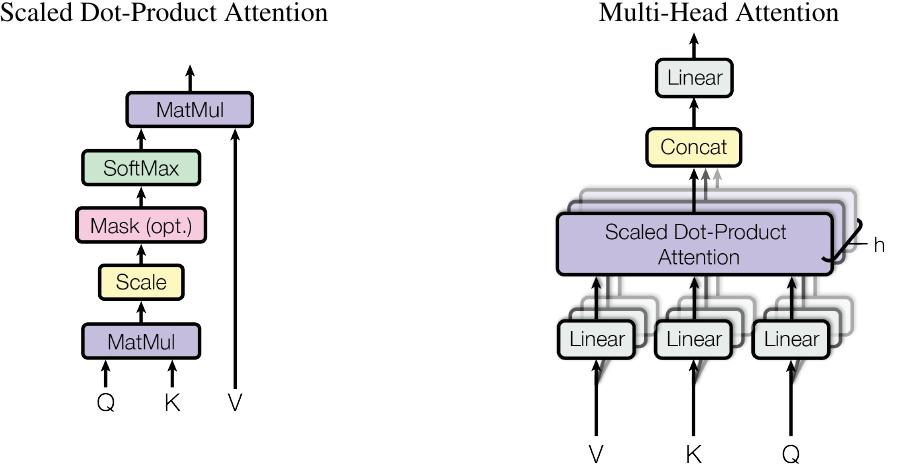

In [ ]:
response = chain_with_sources.invoke(
    "What is multihead?"
)

print("Response:", response['response'])

print("\n\nContext:")
for text in response['context']['texts']:
    print(text.text)
    print("Page number: ", text.metadata.page_number)
    print("\n" + "-"*50 + "\n")
for image in response['context']['images']:
    display_base64_image(image)

## References

- [LangChain Inspiration](https://github.com/langchain-ai/langchain/blob/master/cookbook/Semi_structured_and_multi_modal_RAG.ipynb?ref=blog.langchain.dev)
- [Multivector Storage](https://python.langchain.com/docs/how_to/multi_vector/)